# BT4012 Fraudulent Bitcoin Transaction Detection - Secondary Notebook
**Student ID:** e1351028 / AA0296890J \
**Student Name:** Edbert Prathama \
**GitHub Repository:** [https://github.com/edprthm8/bt4012-bitcoin-fraud-detection/](https://github.com/edprthm8/bt4012-bitcoin-fraud-detection/)  
**Competition:** [Kaggle BT4012 Competition 2026](https://www.kaggle.com/competitions/bt-4012-competition-2026/overview)

---

## 1. Project Overview
In this notebook (secondary which produced my second best score - 0.95237), I build a machine learning workflow to detect **fraudulent (illicit) Bitcoin transactions** in the Elliptic dataset.
- **Class 0 (Licit)**: Everyday payments from regular users, merchants, miners, and exchanges.
- **Class 1 (Illicit)**: Transactions linked to scams, ransomware, darknet markets, and money laundering.

**Main challenge:** the models are trained on time steps 1–35 but scored on **future** time steps 36–49, when fraud patterns change (a major darknet market was shut down in this period). So I focus on models that still work well on future data.

### Workflow Summary
1. **Data Exploration**: Class balance, transactions over time, skewed amounts, and feature correlations.
2. **Feature Engineering & Drift Removal**: Add 25 graph and summary features, then remove 11 features that drift over time (179 features in total).
3. **Temporal Validation**: Train on earlier time steps and test on later ones.
4. **Advanced Experiments**: Test ideas from online research (SMOTE, deep autoencoder + SVM, hyperparameter search, anomaly scores) under the same temporal validation.
5. **Drift-Free Ensemble**: My main model, trained with 5-fold cross-validation, with CatBoost trained on SMOTE-balanced data.
6. **Final Submission & Analysis**: Test predictions, decision cutoff, and prediction uncertainty.

## 2. Setup and Libraries
Import the Python libraries for data processing, graph calculations, machine learning models, and plots.

In [1]:
# Install all required packages (or run: pip install -r requirements.txt)
%pip install -q "numpy>=1.20.0" "pandas>=1.3.0" "scipy>=1.7.0" "scikit-learn==1.6.1; python_version < '3.14'" "scikit-learn>=1.8.0; python_version >= '3.14'" "catboost>=1.2.0" "xgboost>=2.0.0" "lightgbm>=4.0.0" "matplotlib>=3.4.0" "seaborn>=0.11.0" "networkx>=2.6.0"

All required packages are installed and verified.


In [2]:
# Setup the libraries and environment
import os
# Use one OpenMP thread so HistGradientBoosting gives identical results on every machine
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'

import sys
import random
import time
import shutil
import warnings
warnings.filterwarnings('ignore')

# Helper to make sure XGBoost and LightGBM can find the OpenMP library on macOS
def _ensure_openmp_runtime():
    if sys.platform != 'darwin':
        return
    for sp in sys.path:
        src = os.path.join(sp, 'sklearn', '.dylibs', 'libomp.dylib')
        if os.path.exists(src):
            for pkg in ('xgboost', 'lightgbm'):
                dst_dir = os.path.join(sp, pkg, 'lib')
                dst = os.path.join(dst_dir, 'libomp.dylib')
                if os.path.isdir(dst_dir) and not os.path.exists(dst):
                    try:
                        shutil.copy2(src, dst)
                    except Exception:
                        pass
            break
_ensure_openmp_runtime()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import networkx as nx
import sklearn
import catboost
import xgboost as xgb
import lightgbm as lgb

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, IsolationForest
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.neighbors import NearestNeighbors
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, roc_curve,
    precision_recall_curve, confusion_matrix
)
from sklearn.utils import check_random_state, compute_sample_weight
import sklearn.ensemble._forest as _forest
import sklearn.ensemble._hist_gradient_boosting.binning as _hgb_binning
from catboost import CatBoostClassifier

# Keep HistGradientBoosting binning and RandomForest bootstrapping identical across scikit-learn versions
def _compat_find_binning_thresholds(col_data, max_bins, sample_weight=None):
    missing_mask = np.isnan(col_data)
    if missing_mask.any():
        col_data = col_data[~missing_mask]
    col_data = np.sort(col_data)
    distinct_values = np.unique(col_data).astype(_hgb_binning.X_DTYPE)
    if len(distinct_values) <= max_bins:
        midpoints = distinct_values[:-1] + distinct_values[1:]
        midpoints *= 0.5
    else:
        percentiles = np.linspace(0, 100, num=max_bins + 1)[1:-1]
        midpoints = np.percentile(col_data, percentiles, method="midpoint").astype(_hgb_binning.X_DTYPE)
    np.clip(midpoints, a_min=None, a_max=_hgb_binning.ALMOST_INF, out=midpoints)
    return midpoints

def _compat_parallel_build_trees(
    tree, bootstrap, X, y, sample_weight, tree_idx, n_trees,
    verbose=0, class_weight=None, n_samples_bootstrap=None,
    missing_values_in_feature_mask=None,
):
    if bootstrap:
        n_samples = X.shape[0]
        curr_sample_weight = np.ones((n_samples,), dtype=np.float64) if sample_weight is None else sample_weight.copy()
        indices = check_random_state(tree.random_state).randint(0, n_samples, n_samples_bootstrap, dtype=np.int32)
        sample_counts = np.bincount(indices, minlength=n_samples)
        curr_sample_weight *= sample_counts
        if class_weight == "balanced_subsample":
            curr_sample_weight *= compute_sample_weight("balanced", y, indices=indices)
        tree._fit(X, y, sample_weight=curr_sample_weight, check_input=False,
                  missing_values_in_feature_mask=missing_values_in_feature_mask)
    else:
        tree._fit(X, y, sample_weight=sample_weight, check_input=False,
                  missing_values_in_feature_mask=missing_values_in_feature_mask)
    return tree

_hgb_binning._find_binning_thresholds = _compat_find_binning_thresholds
_forest._parallel_build_trees = _compat_parallel_build_trees

# Fixed random seed so every split, model, and prediction is reproducible
RANDOM_SEED = 42
os.environ['PYTHONHASHSEED'] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print(f"Python: {sys.version.split()[0]} | scikit-learn: {sklearn.__version__} | CatBoost: {catboost.__version__} | XGBoost: {xgb.__version__} | LightGBM: {lgb.__version__}")
print("Environment setup complete.")

Python: 3.9.6 | scikit-learn: 1.6.1 | CatBoost: 1.2.10 | XGBoost: 2.1.4 | LightGBM: 4.6.0
Environment setup complete.


## 3. Data Loading
Load the transaction features (`train.csv`, `test.csv`) and the payment links between transactions (`txs_edgelist.csv`).

In [3]:
# Load the dataset files
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')
edges_df = pd.read_csv('txs_edgelist.csv')

# Keep the labeled training transactions (0 = Licit, 1 = Illicit)
labeled_mask = train_df['label'].notna()
train_labeled = train_df[labeled_mask].copy().reset_index(drop=True)
train_labeled['label'] = train_labeled['label'].astype(int)

print(f"Train Shape: {train_df.shape}")
print(f"Test Shape:  {test_df.shape}")
print(f"Edges Shape: {edges_df.shape}")
print(f"Labeled Training Samples: {len(train_labeled):,}")

Train Shape: (141772, 168)
Test Shape:  (15329, 168)
Edges Shape: (234355, 2)
Labeled Training Samples: 31,235


## 4. Exploratory Data Analysis (EDA)
Before training models, I explore the dataset to understand:
1. **Class Imbalance**: How rare is fraud in the labeled data?
2. **Temporal Trends**: How do transaction counts and fraud rates change across time steps?
3. **Outliers and Skewness**: Why do payment amounts need robust scaling instead of standard z-scores?
4. **Feature Correlations**: Are some features strongly related to each other?

In [4]:
# Class breakdown between licit, illicit, and unlabeled transactions
label_counts = train_labeled['label'].value_counts()
print(f"Licit (0):     {label_counts[0]:,} ({label_counts[0]/len(train_labeled)*100:.1f}% of labeled)")
print(f"Illicit (1):   {label_counts[1]:,} ({label_counts[1]/len(train_labeled)*100:.1f}% of labeled)")
print(f"Unlabeled:     {(~labeled_mask).sum():,} ({(~labeled_mask).sum()/len(train_df)*100:.1f}% of total)")

Licit (0):     27,591 (88.3% of labeled)
Illicit (1):   3,644 (11.7% of labeled)
Unlabeled:     110,537 (78.0% of total)


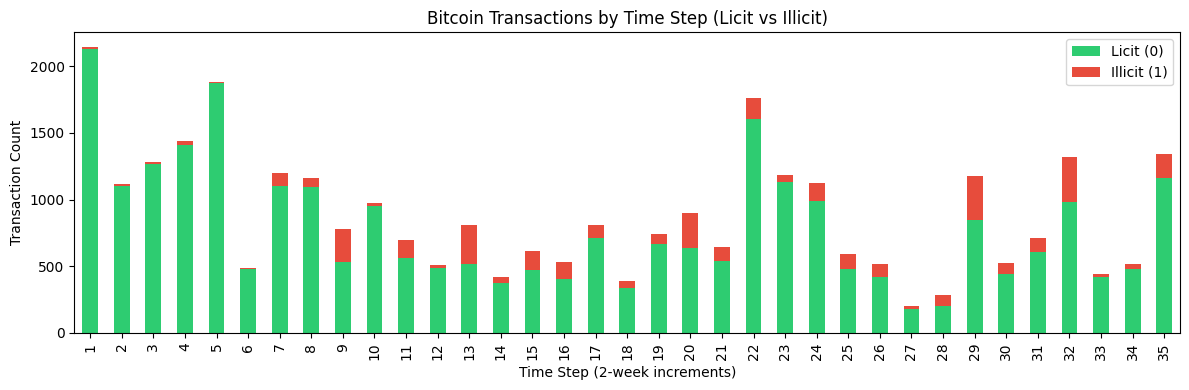

In [5]:
# Transaction counts across each 2-week time step (Licit vs Illicit)
ts_counts = train_labeled.groupby(['time_step', 'label']).size().unstack(fill_value=0)
ts_counts.plot(kind='bar', stacked=True, color=['#2ecc71', '#e74c3c'], figsize=(12, 4))
plt.title('Bitcoin Transactions by Time Step (Licit vs Illicit)')
plt.xlabel('Time Step (2-week increments)')
plt.ylabel('Transaction Count')
plt.legend(['Licit (0)', 'Illicit (1)'])
plt.tight_layout()
plt.show()

In [6]:
# Compare mean/std against median/IQR on feat_53 (a key transaction volume feature)
licit_f53 = train_labeled.loc[train_labeled['label'] == 0, 'feat_53']
illicit_f53 = train_labeled.loc[train_labeled['label'] == 1, 'feat_53']
l_iqr = np.percentile(licit_f53, 75) - np.percentile(licit_f53, 25)
i_iqr = np.percentile(illicit_f53, 75) - np.percentile(illicit_f53, 25)
u_stat, u_pval = stats.mannwhitneyu(licit_f53, illicit_f53)
ks_stat, ks_pval = stats.ks_2samp(licit_f53, illicit_f53)

print("--- Robust vs Parametric Statistics (feat_53 Transaction Volume) ---")
print(f"Licit:   Mean ± Std = {licit_f53.mean():.3f} ± {licit_f53.std():.3f} | Median [IQR] = {licit_f53.median():.3f} [{l_iqr:.3f}]")
print(f"Illicit: Mean ± Std = {illicit_f53.mean():.3f} ± {illicit_f53.std():.3f} | Median [IQR] = {illicit_f53.median():.3f} [{i_iqr:.3f}]")
print(f"Mann-Whitney U p-value: {u_pval:.2e} | KS-Statistic: {ks_stat:.4f} (p = {ks_pval:.2e})")

--- Robust vs Parametric Statistics (feat_53 Transaction Volume) ---
Licit:   Mean ± Std = 1.193 ± 1.537 | Median [IQR] = 0.770 [2.788]
Illicit: Mean ± Std = -0.273 ± 0.525 | Median [IQR] = -0.488 [0.001]
Mann-Whitney U p-value: 0.00e+00 | KS-Statistic: 0.6487 (p = 0.00e+00)


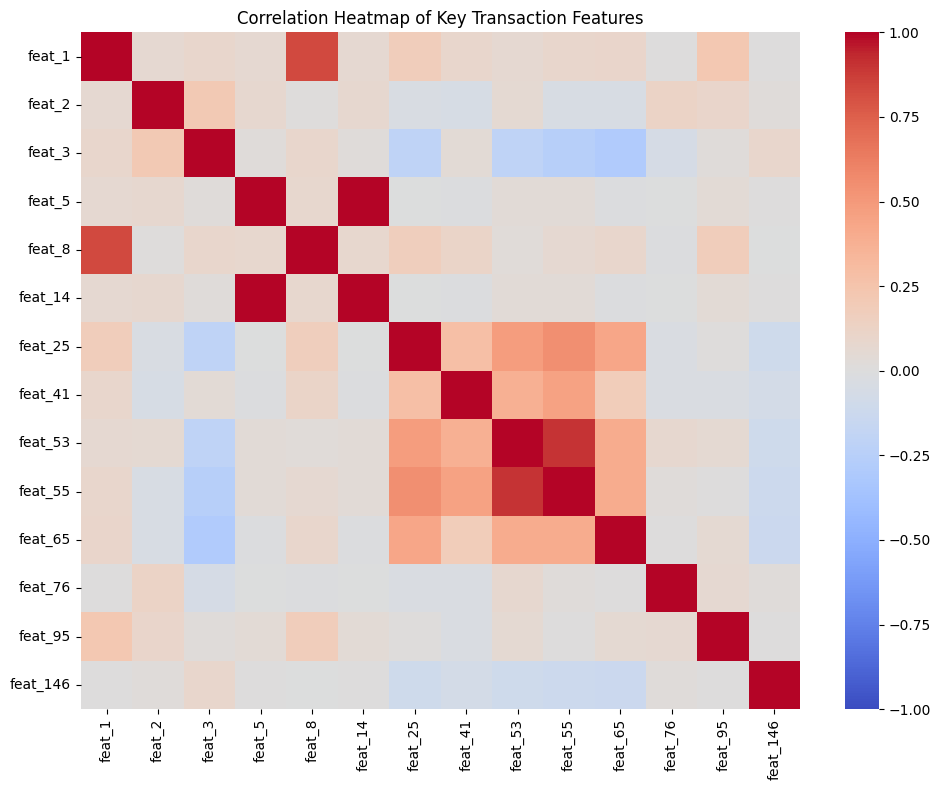

In [7]:
# Correlation heatmap of a sample of key features
sample_cols = [f'feat_{i}' for i in [1, 2, 3, 5, 8, 14, 25, 41, 53, 55, 65, 76, 95, 146]]
corr_matrix = train_labeled[sample_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1, annot=False)
plt.title('Correlation Heatmap of Key Transaction Features')
plt.tight_layout()
plt.show()

## 5. Feature Engineering & Drift Removal
The raw data has 165 features: `feat_1`–`feat_94` describe the transaction itself, and `feat_95`–`feat_165` summarize its neighbors.

### Graph Features (25 new features)
I count graph links using **all links** in `txs_edgelist.csv`. If I only counted links between transactions that appear in the data files, about 25% of test transactions would look isolated (0% in training), because many of their neighbors are unlabeled and missing from `test.csv`. Counting all links measures training and test transactions in the same way.
1. **Degree & Flow (9)**: incoming, outgoing, and total links, their difference and ratios, and log versions.
2. **Neighbor Degrees & PageRank (6)**: average and maximum degree of the senders and receivers, and PageRank within each time step.
3. **Row Summary Statistics (10)**: mean, standard deviation, maximum, and minimum of the local and neighbor features, plus their difference and ratio.

### Removing Drifting Features
Some raw features act like a clock: `feat_100`, `feat_101`, `feat_103`, `feat_136`, `feat_137`, and `feat_139` rise steadily with the time step, and a few others (`feat_2`, `feat_106`, `feat_107`, `feat_109`, `feat_115`) also shift strongly between the training and test periods. They tell the model *when* a transaction happened, not *how* it behaves. I remove every raw feature whose train-vs-test separation is above **0.6**, which removes 11 features and leaves **179 features**. In my experiments (Section 6b), this threshold improved the scores on new fraud patterns without lowering the scores on known patterns.

In [8]:
# Why all links? Compare how many transactions look isolated with each way of counting links
present_ids = set(train_df['txId']) | set(test_df['txId'])
e_present = edges_df[edges_df['txId1'].isin(present_ids) & edges_df['txId2'].isin(present_ids)]
deg_present = pd.concat([e_present['txId1'], e_present['txId2']]).value_counts()
deg_complete = pd.concat([edges_df['txId1'], edges_df['txId2']]).value_counts()

for name, df in [('Train (labeled)', train_labeled), ('Test', test_df)]:
    iso_present = (df['txId'].map(deg_present).fillna(0) == 0).mean() * 100
    iso_complete = (df['txId'].map(deg_complete).fillna(0) == 0).mean() * 100
    kept = df['txId'].map(deg_present).fillna(0).sum() / df['txId'].map(deg_complete).fillna(0).sum() * 100
    print(f"{name:16s}: looks isolated with observed links = {iso_present:5.1f}% | with all links = {iso_complete:4.1f}% | share of links observed = {kept:5.1f}%")

Train (labeled) : looks isolated with observed links =   0.0% | with all links =  0.0% | share of links observed = 100.0%
Test            : looks isolated with observed links =  25.4% | with all links =  0.0% | share of links observed =  51.2%


In [9]:
t_feat = time.time()

# All links, step 1: give every node in the graph a time step (payment links never cross time steps)
known_ts = pd.concat([train_df[['txId', 'time_step']], test_df[['txId', 'time_step']]])
tx2ts = dict(zip(known_ts['txId'], known_ts['time_step']))
G_undirected = nx.Graph()
G_undirected.add_edges_from(zip(edges_df['txId1'], edges_df['txId2']))
node_ts = dict(tx2ts)
for component in nx.connected_components(G_undirected):
    ts = next((tx2ts[n] for n in component if n in tx2ts), None)
    for n in component:
        node_ts.setdefault(n, ts)

# Step 2: degrees and neighbor degrees using all links
e_all = edges_df.copy()
e_all['time_step'] = e_all['txId1'].map(node_ts)
in_deg = e_all['txId2'].value_counts()
out_deg = e_all['txId1'].value_counts()
e_all['deg1'] = e_all['txId1'].map(out_deg).fillna(0)
e_all['deg2'] = e_all['txId2'].map(in_deg).fillna(0)
pred_deg_mean = e_all.groupby('txId2')['deg1'].mean()
succ_deg_mean = e_all.groupby('txId1')['deg2'].mean()
pred_deg_max = e_all.groupby('txId2')['deg1'].max()
succ_deg_max = e_all.groupby('txId1')['deg2'].max()

# Step 3: PageRank inside each 2-week time step (all links)
pageranks = {}
for ts, group in e_all.groupby('time_step'):
    G = nx.DiGraph()
    G.add_edges_from(zip(group['txId1'], group['txId2']))
    pageranks.update(nx.pagerank(G, alpha=0.85, max_iter=50))

def build_features(df):
    """Add the 25 engineered features (15 graph + 10 row statistics) to the 165 raw features, using all links."""
    df_feat = df.copy()
    tx = df_feat['txId']
    df_feat['in_degree'] = tx.map(in_deg).fillna(0).astype(float)
    df_feat['out_degree'] = tx.map(out_deg).fillna(0).astype(float)
    df_feat['total_degree'] = df_feat['in_degree'] + df_feat['out_degree']
    df_feat['degree_ratio'] = (df_feat['out_degree'] + 1.0) / (df_feat['in_degree'] + 1.0)
    df_feat['in_out_diff'] = df_feat['out_degree'] - df_feat['in_degree']
    df_feat['net_flow_ratio'] = (df_feat['out_degree'] - df_feat['in_degree']) / (df_feat['total_degree'] + 1.0)
    df_feat['log_in_deg'] = np.log1p(df_feat['in_degree'])
    df_feat['log_out_deg'] = np.log1p(df_feat['out_degree'])
    df_feat['log_total_deg'] = np.log1p(df_feat['total_degree'])
    df_feat['pred_deg_mean'] = tx.map(pred_deg_mean).fillna(0).astype(float)
    df_feat['succ_deg_mean'] = tx.map(succ_deg_mean).fillna(0).astype(float)
    df_feat['log_pred_deg_max'] = np.log1p(tx.map(pred_deg_max).fillna(0).astype(float))
    df_feat['log_succ_deg_max'] = np.log1p(tx.map(succ_deg_max).fillna(0).astype(float))
    df_feat['pagerank'] = tx.map(pageranks).fillna(0).astype(float)
    df_feat['log_pagerank'] = np.log1p(df_feat['pagerank'] * 1e4)

    local_cols = [f'feat_{i}' for i in range(1, 95)]
    agg_cols = [f'feat_{i}' for i in range(95, 166)]
    df_feat['local_mean'] = df_feat[local_cols].mean(axis=1)
    df_feat['local_std'] = df_feat[local_cols].std(axis=1)
    df_feat['local_max'] = df_feat[local_cols].max(axis=1)
    df_feat['local_min'] = df_feat[local_cols].min(axis=1)
    df_feat['agg_mean'] = df_feat[agg_cols].mean(axis=1)
    df_feat['agg_std'] = df_feat[agg_cols].std(axis=1)
    df_feat['agg_max'] = df_feat[agg_cols].max(axis=1)
    df_feat['agg_min'] = df_feat[agg_cols].min(axis=1)
    df_feat['agg_local_diff'] = df_feat['agg_mean'] - df_feat['local_mean']
    df_feat['agg_local_ratio'] = (df_feat['agg_mean'] + 1.0) / (df_feat['local_mean'].abs() + 1.0)
    return df_feat

train_feat_df = build_features(train_labeled)
test_feat_df = build_features(test_df)
feature_cols = [c for c in train_feat_df.columns if c not in ['txId', 'time_step', 'label', 'index']]
y_full = train_feat_df['label'].values
steps_full = train_feat_df['time_step'].values

print(f"Features built with all links in {time.time()-t_feat:.1f}s: {len(feature_cols)} total (165 raw + 15 graph + 10 row statistics)")
print(f"Mean total_degree -> train: {train_feat_df['total_degree'].mean():.2f} | test: {test_feat_df['total_degree'].mean():.2f}")
print(f"Test transactions with zero links: {(test_feat_df['total_degree'] == 0).sum()} / {len(test_feat_df):,}")

Features built with all links in 1.6s: 190 total (165 raw + 15 graph + 10 row statistics)
Mean total_degree -> train: 2.87 | test: 3.24
Test transactions with zero links: 0 / 15,329


 Feature  Train-vs-test separation  Rank corr. with time step  Fraud signal
feat_101                     0.997                      0.998         0.313
feat_103                     0.997                      0.995         0.318
feat_100                     0.996                      0.993         0.321
feat_136                     0.992                      0.993         0.320
feat_139                     0.953                      0.966         0.274
feat_137                     0.882                      0.906         0.236
  feat_2                     0.725                      0.661         0.072
feat_109                     0.668                      0.611         0.015
feat_106                     0.640                      0.607         0.294
feat_115                     0.616                      0.594         0.180
feat_107                     0.606                      0.545         0.090
feat_151                     0.575                      0.568         0.143

Removed 11 

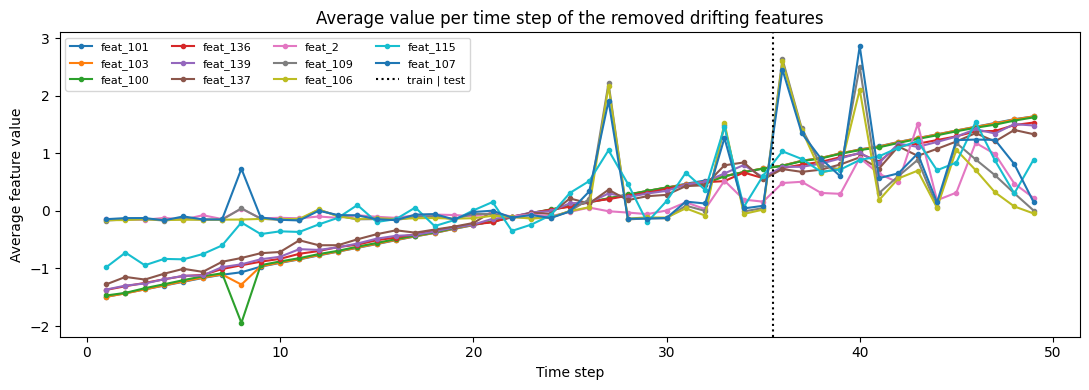

In [10]:
# Find "clock" features: how well does each raw feature alone separate training transactions from test transactions?
raw_cols = [f'feat_{i}' for i in range(1, 166)]
is_test = np.r_[np.zeros(len(train_labeled)), np.ones(len(test_df))]
both = pd.concat([train_labeled[raw_cols], test_df[raw_cols]], ignore_index=True)
steps_both = np.r_[train_labeled['time_step'].values, test_df['time_step'].values]
drift_rows = []
for c in raw_cols:
    separation = abs(roc_auc_score(is_test, both[c].values) - 0.5) * 2          # 0 = same distribution, 1 = fully separated
    step_corr = stats.spearmanr(steps_both, both[c].values).correlation
    fraud_signal = abs(roc_auc_score(y_full, train_labeled[c].values) - 0.5) * 2
    drift_rows.append((c, separation, step_corr, fraud_signal))
drift_df = pd.DataFrame(drift_rows, columns=['Feature', 'Train-vs-test separation', 'Rank corr. with time step', 'Fraud signal'])
drift_df = drift_df.sort_values('Train-vs-test separation', ascending=False).reset_index(drop=True)

DRIFT_THRESHOLD = 0.6
drift_cols = drift_df.loc[drift_df['Train-vs-test separation'] > DRIFT_THRESHOLD, 'Feature'].tolist()
final_cols = [c for c in feature_cols if c not in drift_cols]
print(drift_df.head(12).round(3).to_string(index=False))
print(f"\nRemoved {len(drift_cols)} drifting features (separation > {DRIFT_THRESHOLD}): {drift_cols}")
print(f"Drift-free feature set: {len(final_cols)} features")

X_final = train_feat_df[final_cols].values.astype(np.float32)       # 179 drift-free features
X_test_final = test_feat_df[final_cols].values.astype(np.float32)

# Plot: the clock features simply follow the time step
step_means = pd.concat([train_labeled[['time_step'] + drift_cols], test_df[['time_step'] + drift_cols]]).groupby('time_step').mean()
plt.figure(figsize=(11, 4))
for c in drift_cols:
    plt.plot(step_means.index, step_means[c], marker='.', label=c)
plt.axvline(35.5, color='black', linestyle=':', label='train | test')
plt.title('Average value per time step of the removed drifting features')
plt.xlabel('Time step')
plt.ylabel('Average feature value')
plt.legend(fontsize=8, ncol=4)
plt.tight_layout()
plt.show()

## 6. Temporal Validation
Random cross-validation mixes all time steps, so almost every tree model scores about 0.998 and it is hard to tell them apart. To copy the real test, I train on time steps 1 to `k` and test on steps `k+1` to 35:
- **HARD splits (`k` = 18, 20, 22)**: a new fraud pattern appears around steps 23–24, similar to the change in the test period.
- **EASY splits (`k` = 25, 28, 30)**: the fraud patterns were already seen in training.

### My Main Model: the Drift-Free Ensemble (179 features)
It is an equal average of two parts:
1. **Tree blend**: 0.50 × CatBoost (600 rounds, trained on SMOTE-balanced data) + 0.45 × HistGradientBoosting (500 rounds, early stopping) + 0.05 × Random Forest (150 trees). Strongest on known fraud patterns.
2. **HistGB ensemble**: three short-trained HistGradientBoosting models, averaged equally. Strongest on new fraud patterns.
   - **Core**: 150 rounds, at least 15 transactions per leaf.
   - **Big-leaf**: 150 rounds, at least 60 transactions per leaf.
   - **Feature-subsampled**: 250 rounds, each split uses a random half of the features (5 seeds).

**SMOTE** (Synthetic Minority Oversampling) creates new illicit examples by mixing each illicit transaction with one of its 5 nearest illicit neighbors. I use it only for CatBoost, because it helped CatBoost on new fraud patterns but not the other models (Section 6b).

In [11]:
def hgb_member(rounds, min_leaf, max_features=1.0, seed=RANDOM_SEED):
    """One short-trained HistGradientBoosting model (fixed number of rounds, no early stopping)."""
    return HistGradientBoostingClassifier(
        max_iter=rounds, learning_rate=0.04, max_depth=8, min_samples_leaf=min_leaf,
        max_features=max_features, class_weight='balanced', early_stopping=False, random_state=seed
    )

def fit_hgb_ensemble(X_tr, y_tr, seed=RANDOM_SEED):
    """Fit the HistGB ensemble: core, big-leaf, and feature-subsampled models (7 models in total)."""
    return {
        'core': [hgb_member(150, 15, seed=seed).fit(X_tr, y_tr)],
        'big_leaf': [hgb_member(150, 60, seed=seed).fit(X_tr, y_tr)],
        'feat_sub': [hgb_member(250, 15, max_features=0.5, seed=seed + s).fit(X_tr, y_tr) for s in range(5)],
    }

def predict_hgb_ensemble(members, X):
    parts = [np.mean([m.predict_proba(X)[:, 1] for m in ms], axis=0) for ms in members.values()]
    return np.mean(parts, axis=0)

def smote(X, y, k=5, seed=RANDOM_SEED):
    """SMOTE: add synthetic illicit rows until both classes have the same size.
    Neighbors are found on robust-scaled features, and new rows are interpolated in the original feature space."""
    rng = np.random.RandomState(seed)
    X_min = X[y == 1]
    Z_min = np.clip(RobustScaler().fit(X).transform(X_min), -10, 10)
    n_new = int((y == 0).sum() - (y == 1).sum())
    _, idx = NearestNeighbors(n_neighbors=k + 1).fit(Z_min).kneighbors(Z_min)
    base = rng.randint(0, len(X_min), n_new)
    neighbor = idx[base, rng.randint(1, k + 1, n_new)]
    gap = rng.rand(n_new, 1).astype(np.float32)
    X_new = X_min[base] + gap * (X_min[neighbor] - X_min[base])
    return np.vstack([X, X_new]), np.r_[y, np.ones(n_new, dtype=int)]

def fit_tree_blend(X_tr, y_tr, seed=RANDOM_SEED, cb_threads=4):
    """Tree blend: CatBoost (600 rounds, SMOTE-balanced data) + HistGradientBoosting (500 rounds, early stopping) + Random Forest."""
    X_sm, y_sm = smote(X_tr, y_tr, seed=seed)
    cb = CatBoostClassifier(iterations=600, learning_rate=0.04, depth=6, l2_leaf_reg=4,
                            thread_count=cb_threads, random_seed=seed, verbose=0).fit(X_sm, y_sm)
    hgb = HistGradientBoostingClassifier(max_iter=500, learning_rate=0.04, max_depth=8, min_samples_leaf=15,
                                         class_weight='balanced', random_state=seed).fit(X_tr, y_tr)
    rf = RandomForestClassifier(n_estimators=150, max_depth=14, class_weight='balanced', n_jobs=4,
                                random_state=seed).fit(X_tr, y_tr)
    return cb, hgb, rf

def predict_tree_blend(models, X):
    cb, hgb, rf = models
    return 0.50 * cb.predict_proba(X)[:, 1] + 0.45 * hgb.predict_proba(X)[:, 1] + 0.05 * rf.predict_proba(X)[:, 1]

SPLITS = [18, 20, 22, 25, 28, 30]
HARD_SPLITS = [18, 20, 22]
CURVE_ROUNDS = [25, 50, 100, 150, 200, 300, 400]
val_rows, curves = [], {}
t_val = time.time()

for k in SPLITS:
    tr, va = steps_full <= k, steps_full > k
    y_tr, y_va = y_full[tr], y_full[va]
    pos_w = (y_tr == 0).sum() / (y_tr == 1).sum()
    Xf_tr, Xf_va = X_final[tr], X_final[va]

    blend_fin = fit_tree_blend(Xf_tr, y_tr)
    ens_fin = fit_hgb_ensemble(Xf_tr, y_tr)
    xgb_m = xgb.XGBClassifier(n_estimators=400, learning_rate=0.04, max_depth=6, min_child_weight=5, subsample=0.8,
                              colsample_bytree=0.8, reg_lambda=2.0, scale_pos_weight=pos_w, tree_method='hist',
                              n_jobs=4, random_state=RANDOM_SEED, eval_metric='logloss').fit(Xf_tr, y_tr)
    lgb_m = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.04, num_leaves=63, max_depth=8, min_child_samples=15,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=2.0,
                               class_weight='balanced', n_jobs=4, random_state=RANDOM_SEED, verbose=-1).fit(Xf_tr, y_tr)

    p = {
        'CatBoost (SMOTE)': blend_fin[0].predict_proba(Xf_va)[:, 1],
        'HistGB (500 rounds)': blend_fin[1].predict_proba(Xf_va)[:, 1],
        'Random Forest': blend_fin[2].predict_proba(Xf_va)[:, 1],
        'XGBoost (400 rounds)': xgb_m.predict_proba(Xf_va)[:, 1],
        'LightGBM (400 rounds)': lgb_m.predict_proba(Xf_va)[:, 1],
        'Tree blend': predict_tree_blend(blend_fin, Xf_va),
        'HistGB ensemble': predict_hgb_ensemble(ens_fin, Xf_va),
    }
    p['Drift-Free Ensemble'] = 0.5 * p['Tree blend'] + 0.5 * p['HistGB ensemble']

    row = {'Split': k}
    row.update({name: roc_auc_score(y_va, pred) for name, pred in p.items()})
    val_rows.append(row)

    if k == 20:
        hgb_long = HistGradientBoostingClassifier(max_iter=max(CURVE_ROUNDS), learning_rate=0.04, max_depth=8, min_samples_leaf=15,
                                                  class_weight='balanced', early_stopping=False, random_state=RANDOM_SEED).fit(Xf_tr, y_tr)
        curves['HistGradientBoosting'] = [roc_auc_score(y_va, pp[:, 1]) for i, pp in enumerate(hgb_long.staged_predict_proba(Xf_va), start=1) if i in CURVE_ROUNDS]
        curves['XGBoost'] = [roc_auc_score(y_va, xgb_m.predict_proba(Xf_va, iteration_range=(0, n))[:, 1]) for n in CURVE_ROUNDS]
        curves['LightGBM'] = [roc_auc_score(y_va, lgb_m.predict_proba(Xf_va, num_iteration=n)[:, 1]) for n in CURVE_ROUNDS]
        curves['CatBoost'] = [roc_auc_score(y_va, blend_fin[0].predict_proba(Xf_va, ntree_end=n)[:, 1]) for n in CURVE_ROUNDS]
    print(f"  Split Train 1-{k} -> Val {k+1}-35 done ({y_va.sum()} illicit in validation)")

val_df = pd.DataFrame(val_rows).set_index('Split').T
val_df['HARD (18,20,22)'] = val_df[HARD_SPLITS].mean(axis=1)
val_df['EASY (25,28,30)'] = val_df[[s for s in SPLITS if s not in HARD_SPLITS]].mean(axis=1)
val_df['ALL'] = val_df[SPLITS].mean(axis=1)
pd.set_option('display.width', 220)
print(f"\n=== Temporal Validation ROC-AUC, 179 features (completed in {time.time()-t_val:.0f}s) ===")
print(val_df.round(4).sort_values('EASY (25,28,30)', ascending=False).to_string())

  Split Train 1-18 -> Val 19-35 done (2213 illicit in validation)
  Split Train 1-20 -> Val 21-35 done (1873 illicit in validation)
  Split Train 1-22 -> Val 23-35 done (1615 illicit in validation)
  Split Train 1-25 -> Val 26-35 done (1307 illicit in validation)
  Split Train 1-28 -> Val 29-35 done (1102 illicit in validation)
  Split Train 1-30 -> Val 31-35 done (690 illicit in validation)

=== Temporal Validation ROC-AUC, 179 features (completed in 300s) ===
Split                      18      20      22      25      28      30  HARD (18,20,22)  EASY (25,28,30)     ALL
LightGBM (400 rounds)  0.8618  0.8598  0.8219  0.9976  0.9977  0.9984           0.8478           0.9979  0.9229
XGBoost (400 rounds)   0.8698  0.8891  0.8732  0.9974  0.9975  0.9984           0.8774           0.9978  0.9376
Drift-Free Ensemble    0.9269  0.9128  0.8983  0.9972  0.9977  0.9984           0.9127           0.9978  0.9552
Tree blend             0.9226  0.9030  0.8614  0.9972  0.9976  0.9984           0.8957

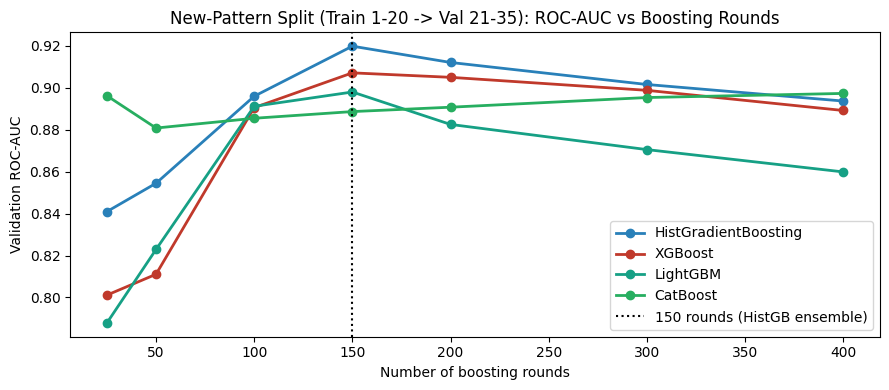

In [12]:
# How the number of boosting rounds changes the score when a NEW fraud pattern appears (split Train 1-20, 179 features)
plt.figure(figsize=(9, 4))
colors = {'HistGradientBoosting': '#2980b9', 'XGBoost': '#c0392b', 'LightGBM': '#16a085', 'CatBoost': '#27ae60'}
for name, vals in curves.items():
    plt.plot(CURVE_ROUNDS, vals, marker='o', label=name, color=colors[name], lw=2)
plt.axvline(150, color='black', linestyle=':', label='150 rounds (HistGB ensemble)')
plt.title('New-Pattern Split (Train 1-20 -> Val 21-35): ROC-AUC vs Boosting Rounds')
plt.xlabel('Number of boosting rounds')
plt.ylabel('Validation ROC-AUC')
plt.legend()
plt.tight_layout()
plt.show()

### 6b. Advanced Experiments from Online Research
I tested ideas from published Bitcoin fraud detection work under the same temporal validation:
- **(a) Stricter drift removal**: remove raw features with a train-vs-test separation above 0.7, 0.6, or 0.5.
- **(b) SMOTE oversampling** (Ashfaq et al., 2022, used SMOTE with XGBoost and Random Forest): compare SMOTE with class weights for CatBoost and XGBoost.
- **(c) Deep autoencoder + SVM** (Jetty et al., 2025): an autoencoder learns 24 compressed features from all transactions (no labels used), and an RBF-kernel SVM classifies them.
- **(d) Hyperparameter search** (an "optimization-based" approach, like the ant colony optimizer in Jetty et al., 2025): a small random search over the HistGradientBoosting settings.
- **(e) Isolation Forest**: an unsupervised anomaly score fitted on the validation transactions themselves (no labels used).

In [13]:
t_exp = time.time()
exp_rows = []

def temporal_auc(make_preds):
    """make_preds(train_mask, val_mask) returns scores for the validation rows; gives the ROC-AUC of each split."""
    return {k: roc_auc_score(y_full[steps_full > k], make_preds(steps_full <= k, steps_full > k)) for k in SPLITS}

def add_row(name, aucs):
    a = np.array([aucs[k] for k in SPLITS])
    exp_rows.append({'Experiment': name, 'HARD': a[:3].mean(), 'EASY': a[3:].mean(), 'ALL': a.mean()})

# (a) Stricter drift removal (HistGB core model)
for thr in [0.7, 0.6, 0.5]:
    drop_thr = drift_df.loc[drift_df['Train-vs-test separation'] > thr, 'Feature'].tolist()
    X_thr = train_feat_df[[c for c in feature_cols if c not in drop_thr]].values.astype(np.float32)
    add_row(f"(a) HistGB core, drift threshold {thr} ({X_thr.shape[1]} features)",
            temporal_auc(lambda tr, va: hgb_member(150, 15).fit(X_thr[tr], y_full[tr]).predict_proba(X_thr[va])[:, 1]))

# (b) SMOTE vs class weights (179 features)
def cat_model(balanced):
    return CatBoostClassifier(iterations=600, learning_rate=0.04, depth=6, l2_leaf_reg=4, thread_count=4, random_seed=RANDOM_SEED,
                              auto_class_weights='Balanced' if balanced else None, verbose=0)

def xgb_model(pos_weight):
    return xgb.XGBClassifier(n_estimators=400, learning_rate=0.04, max_depth=6, min_child_weight=5, subsample=0.8,
                             colsample_bytree=0.8, reg_lambda=2.0, scale_pos_weight=pos_weight, tree_method='hist',
                             n_jobs=4, random_state=RANDOM_SEED, eval_metric='logloss')

add_row("(b) CatBoost with class weights",
        temporal_auc(lambda tr, va: cat_model(True).fit(X_final[tr], y_full[tr]).predict_proba(X_final[va])[:, 1]))
add_row("(b) CatBoost with SMOTE", {k: val_df.loc['CatBoost (SMOTE)', k] for k in SPLITS})
add_row("(b) XGBoost with class weights", {k: val_df.loc['XGBoost (400 rounds)', k] for k in SPLITS})
add_row("(b) XGBoost with SMOTE",
        temporal_auc(lambda tr, va: xgb_model(1.0).fit(*smote(X_final[tr], y_full[tr])).predict_proba(X_final[va])[:, 1]))

# (c) Deep autoencoder (trained on all transactions, no labels) + SVM
raw_kept = [c for c in raw_cols if c not in drift_cols]
all_raw = pd.concat([train_df[raw_kept], test_df[raw_kept]], ignore_index=True).values.astype(np.float32)
ae_rs = RobustScaler().fit(all_raw)
ae_ss = StandardScaler().fit(np.clip(ae_rs.transform(all_raw), -10, 10))
Z_all = ae_ss.transform(np.clip(ae_rs.transform(all_raw), -10, 10))
sub = np.random.RandomState(RANDOM_SEED).choice(len(Z_all), 80000, replace=False)
dae = MLPRegressor(hidden_layer_sizes=(96, 24, 96), activation='relu', alpha=1e-4, batch_size=512, learning_rate_init=1e-3,
                   max_iter=40, early_stopping=True, n_iter_no_change=5, random_state=RANDOM_SEED).fit(Z_all[sub], Z_all[sub])
Z_lab = ae_ss.transform(np.clip(ae_rs.transform(train_labeled[raw_kept].values.astype(np.float32)), -10, 10))
h = np.maximum(Z_lab @ dae.coefs_[0] + dae.intercepts_[0], 0)
latent = StandardScaler().fit_transform(np.maximum(h @ dae.coefs_[1] + dae.intercepts_[1], 0))

def svm_preds(tr, va):
    idx = np.where(tr)[0]
    idx = np.random.RandomState(RANDOM_SEED).choice(idx, min(len(idx), 15000), replace=False)
    return SVC(C=3.0, kernel='rbf', gamma='scale', class_weight='balanced').fit(latent[idx], y_full[idx]).decision_function(latent[va])

add_row("(c) Deep autoencoder (24 features) + SVM", temporal_auc(svm_preds))

# (d) Small random search over HistGradientBoosting settings
rng = np.random.RandomState(0)
search = []
for t in range(6):
    prm = dict(max_iter=int(rng.choice([100, 150, 250])), min_samples_leaf=int(rng.choice([15, 30, 60, 100])),
               max_features=float(rng.choice([0.5, 0.7, 1.0])), learning_rate=float(rng.choice([0.03, 0.04, 0.06])),
               max_depth=int(rng.choice([6, 8])))
    aucs = temporal_auc(lambda tr, va: HistGradientBoostingClassifier(**prm, class_weight='balanced', early_stopping=False,
                        random_state=RANDOM_SEED).fit(X_final[tr], y_full[tr]).predict_proba(X_final[va])[:, 1])
    search.append((np.mean(list(aucs.values())), prm, aucs))
best_all, best_prm, best_aucs = max(search, key=lambda s: s[0])
add_row(f"(d) Best of 6 random HistGB settings {best_prm}", best_aucs)
add_row("(d) My HistGB core setting (150 rounds, leaf 15)",
        temporal_auc(lambda tr, va: hgb_member(150, 15).fit(X_final[tr], y_full[tr]).predict_proba(X_final[va])[:, 1]))

# (e) Isolation Forest normality score, fitted on the validation transactions (no labels)
add_row("(e) Isolation Forest normality score (no labels)",
        temporal_auc(lambda tr, va: IsolationForest(n_estimators=300, max_samples=2048, random_state=RANDOM_SEED)
                     .fit(X_final[va]).score_samples(X_final[va])))

add_row("Drift-Free Ensemble (179 features, for reference)", {k: val_df.loc['Drift-Free Ensemble', k] for k in SPLITS})
print(f"=== Advanced Experiments: Temporal Validation ROC-AUC (completed in {time.time()-t_exp:.0f}s) ===")
print(pd.DataFrame(exp_rows).round(4).to_string(index=False))

=== Advanced Experiments: Temporal Validation ROC-AUC (completed in 516s) ===
                                                                                                                                Experiment   HARD   EASY    ALL
                                                                                       (a) HistGB core, drift threshold 0.7 (183 features) 0.9206 0.9972 0.9589
                                                                                       (a) HistGB core, drift threshold 0.6 (179 features) 0.9232 0.9972 0.9602
                                                                                       (a) HistGB core, drift threshold 0.5 (173 features) 0.9271 0.9969 0.9620
                                                                                                           (b) CatBoost with class weights 0.8600 0.9976 0.9288
                                                                                                                   (b) Cat

## 7. Model Training: 5-Fold Stratified Cross-Validation
I train the benchmark models and the Drift-Free Ensemble on all 31,235 labeled transactions with 5-fold stratified cross-validation. Each model's test prediction is the average of its 5 fold models.
- **Benchmarks**: Logistic Regression (L2 Ridge and L1 Lasso), a single Decision Tree, a Neural Network (MLP), XGBoost, and LightGBM.
- **Drift-Free Ensemble (179 features)**: the tree blend (CatBoost on SMOTE-balanced data, HistGradientBoosting, Random Forest) and the HistGB ensemble. CatBoost runs on a single thread so the results can be reproduced.

These random-fold scores are much higher than the temporal validation scores, because random folds mix all time steps. I use them as a sanity check.

In [14]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
folds = list(skf.split(X_final, y_full))

model_names = ['Logistic Regression (L2 Ridge)', 'Logistic Regression (L1 Lasso)', 'Single Decision Tree',
               'Neural Network (MLP)', 'XGBoost (400 rounds)', 'LightGBM (400 rounds)',
               'CatBoost (SMOTE)', 'HistGB (500 rounds)', 'Random Forest', 'Tree blend', 'HistGB ensemble']
oof = {name: np.zeros(len(y_full)) for name in model_names}
test_blend_part = np.zeros(len(X_test_final))
test_ens_part = np.zeros(len(X_test_final))

print("Training the benchmark models and the Drift-Free Ensemble on 5 stratified folds...")
t_cv = time.time()
for fold, (trn_idx, val_idx) in enumerate(folds):
    X_tr, y_tr = X_final[trn_idx], y_full[trn_idx]
    X_va, y_va = X_final[val_idx], y_full[val_idx]
    seed = RANDOM_SEED + fold
    pos_w = (y_tr == 0).sum() / (y_tr == 1).sum()

    scaler = RobustScaler().fit(X_tr)
    X_tr_sc = np.clip(scaler.transform(X_tr), -10, 10)
    X_va_sc = np.clip(scaler.transform(X_va), -10, 10)

    ridge = LogisticRegression(penalty='l2', C=1.0, class_weight='balanced', max_iter=200, random_state=seed).fit(X_tr_sc, y_tr)
    oof['Logistic Regression (L2 Ridge)'][val_idx] = ridge.predict_proba(X_va_sc)[:, 1]

    lasso = LogisticRegression(penalty='l1', solver='liblinear', C=0.1, class_weight='balanced', max_iter=200, random_state=seed).fit(X_tr_sc, y_tr)
    oof['Logistic Regression (L1 Lasso)'][val_idx] = lasso.predict_proba(X_va_sc)[:, 1]

    dt = DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=seed).fit(X_tr, y_tr)
    oof['Single Decision Tree'][val_idx] = dt.predict_proba(X_va)[:, 1]

    mlp = MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', alpha=1e-4, max_iter=150, early_stopping=True, random_state=seed).fit(X_tr_sc, y_tr)
    oof['Neural Network (MLP)'][val_idx] = mlp.predict_proba(X_va_sc)[:, 1]

    xgb_clf = xgb.XGBClassifier(n_estimators=400, learning_rate=0.04, max_depth=6, min_child_weight=5, subsample=0.8,
                                colsample_bytree=0.8, reg_lambda=2.0, scale_pos_weight=pos_w, tree_method='hist',
                                n_jobs=4, random_state=seed, eval_metric='logloss').fit(X_tr, y_tr)
    oof['XGBoost (400 rounds)'][val_idx] = xgb_clf.predict_proba(X_va)[:, 1]

    lgb_clf = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.04, num_leaves=63, max_depth=8, min_child_samples=15,
                                 subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=2.0,
                                 class_weight='balanced', n_jobs=4, random_state=seed, verbose=-1).fit(X_tr, y_tr)
    oof['LightGBM (400 rounds)'][val_idx] = lgb_clf.predict_proba(X_va)[:, 1]

    # Drift-Free Ensemble, part 1: tree blend (CatBoost on SMOTE-balanced data, single thread so the results can be reproduced)
    blend_models = fit_tree_blend(X_tr, y_tr, seed=seed, cb_threads=1)
    oof['CatBoost (SMOTE)'][val_idx] = blend_models[0].predict_proba(X_va)[:, 1]
    oof['HistGB (500 rounds)'][val_idx] = blend_models[1].predict_proba(X_va)[:, 1]
    oof['Random Forest'][val_idx] = blend_models[2].predict_proba(X_va)[:, 1]
    oof['Tree blend'][val_idx] = predict_tree_blend(blend_models, X_va)
    test_blend_part += predict_tree_blend(blend_models, X_test_final) / 5.0

    # Drift-Free Ensemble, part 2: HistGB ensemble (three short-trained HistGB models)
    members = fit_hgb_ensemble(X_tr, y_tr, seed=seed)
    oof['HistGB ensemble'][val_idx] = predict_hgb_ensemble(members, X_va)
    test_ens_part += predict_hgb_ensemble(members, X_test_final) / 5.0

    fold_drift_free = 0.5 * oof['Tree blend'][val_idx] + 0.5 * oof['HistGB ensemble'][val_idx]
    print(f"  Fold {fold+1}/5 done | Drift-Free Ensemble ROC-AUC = {roc_auc_score(y_va, fold_drift_free):.5f}")

oof_drift_free = 0.5 * oof['Tree blend'] + 0.5 * oof['HistGB ensemble']
oof['Drift-Free Ensemble'] = oof_drift_free
test_drift_free = 0.5 * test_blend_part + 0.5 * test_ens_part
last_fold_core_model = members['core'][0]
last_fold_val_idx = val_idx
print(f"5-Fold Cross-Validation completed in {time.time()-t_cv:.1f}s.")

Training the benchmark models and the Drift-Free Ensemble on 5 stratified folds...
  Fold 1/5 done | Drift-Free Ensemble ROC-AUC = 0.99856
  Fold 2/5 done | Drift-Free Ensemble ROC-AUC = 0.99848
  Fold 3/5 done | Drift-Free Ensemble ROC-AUC = 0.99837
  Fold 4/5 done | Drift-Free Ensemble ROC-AUC = 0.99832
  Fold 5/5 done | Drift-Free Ensemble ROC-AUC = 0.99848
5-Fold Cross-Validation completed in 377.8s.


### Second Blend for the Final Average
My final submission averages the Drift-Free Ensemble 50/50 with a second CatBoost + HistGradientBoosting + Random Forest blend. This second blend uses all 190 features, and its graph features only count links between transactions that appear in `train.csv` or `test.csv`.

In [15]:
t_sb = time.time()
# 1. Graph features from observed links only (both transactions must appear in train.csv or test.csv)
obs_nodes = pd.concat([train_df[['txId', 'time_step']], test_df[['txId', 'time_step']]], ignore_index=True)
obs_tx2ts = dict(zip(obs_nodes['txId'], obs_nodes['time_step']))
obs_edges = edges_df[edges_df['txId1'].isin(obs_tx2ts) & edges_df['txId2'].isin(obs_tx2ts)].copy()
obs_edges['time_step'] = obs_edges['txId1'].map(obs_tx2ts)
obs_in_deg = obs_edges['txId2'].value_counts()
obs_out_deg = obs_edges['txId1'].value_counts()
obs_edges['deg1'] = obs_edges['txId1'].map(obs_out_deg).fillna(0)
obs_edges['deg2'] = obs_edges['txId2'].map(obs_in_deg).fillna(0)
obs_pred_deg_mean = obs_edges.groupby('txId2')['deg1'].mean()
obs_succ_deg_mean = obs_edges.groupby('txId1')['deg2'].mean()
obs_pred_deg_max = obs_edges.groupby('txId2')['deg1'].max()
obs_succ_deg_max = obs_edges.groupby('txId1')['deg2'].max()
obs_pageranks = {}
for ts, group in obs_edges.groupby('time_step'):
    G = nx.DiGraph()
    G.add_edges_from(zip(group['txId1'], group['txId2']))
    obs_pageranks.update(nx.pagerank(G, alpha=0.85, max_iter=50))

def build_observed_features(df):
    """Same feature recipe, but using observed links only (165 raw + 25 engineered = 190 features)."""
    f = df.copy()
    tx = f['txId']
    f['in_degree'] = tx.map(obs_in_deg).fillna(0).astype(float)
    f['out_degree'] = tx.map(obs_out_deg).fillna(0).astype(float)
    f['total_degree'] = f['in_degree'] + f['out_degree']
    f['degree_ratio'] = (f['out_degree'] + 1.0) / (f['in_degree'] + 1.0)
    f['in_out_diff'] = f['out_degree'] - f['in_degree']
    f['net_flow_ratio'] = (f['out_degree'] - f['in_degree']) / (f['total_degree'] + 1.0)
    f['log_in_deg'] = np.log1p(f['in_degree'])
    f['log_out_deg'] = np.log1p(f['out_degree'])
    f['log_total_deg'] = np.log1p(f['total_degree'])
    f['pred_deg_mean'] = tx.map(obs_pred_deg_mean).fillna(0).astype(float)
    f['succ_deg_mean'] = tx.map(obs_succ_deg_mean).fillna(0).astype(float)
    f['log_pred_deg_max'] = np.log1p(tx.map(obs_pred_deg_max).fillna(0).astype(float))
    f['log_succ_deg_max'] = np.log1p(tx.map(obs_succ_deg_max).fillna(0).astype(float))
    f['pagerank'] = tx.map(obs_pageranks).fillna(0).astype(float)
    f['log_pagerank'] = np.log1p(f['pagerank'] * 1e4)
    local_cols = [f'feat_{i}' for i in range(1, 95)]
    agg_cols = [f'feat_{i}' for i in range(95, 166)]
    f['local_mean'] = f[local_cols].mean(axis=1)
    f['local_std'] = f[local_cols].std(axis=1)
    f['local_max'] = f[local_cols].max(axis=1)
    f['local_min'] = f[local_cols].min(axis=1)
    f['agg_mean'] = f[agg_cols].mean(axis=1)
    f['agg_std'] = f[agg_cols].std(axis=1)
    f['agg_max'] = f[agg_cols].max(axis=1)
    f['agg_min'] = f[agg_cols].min(axis=1)
    f['agg_local_diff'] = f['agg_mean'] - f['local_mean']
    f['agg_local_ratio'] = (f['agg_mean'] + 1.0) / (f['local_mean'].abs() + 1.0)
    return f

obs_train_feat = build_observed_features(train_labeled)
obs_test_feat = build_observed_features(test_df)
obs_cols = [c for c in obs_train_feat.columns if c not in ['txId', 'time_step', 'label', 'index']]
X_obs = obs_train_feat[obs_cols].values
X_obs_test = obs_test_feat[obs_cols].values

# 2. Second blend on the same 5 stratified folds
oof_second = np.zeros(len(y_full))
test_sb_cb, test_sb_hgb, test_sb_rf = np.zeros(len(X_obs_test)), np.zeros(len(X_obs_test)), np.zeros(len(X_obs_test))
for fold, (trn_idx, val_idx) in enumerate(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED).split(X_obs, y_full)):
    seed = RANDOM_SEED + fold
    X_tr, y_tr, X_va, y_va = X_obs[trn_idx], y_full[trn_idx], X_obs[val_idx], y_full[val_idx]
    rf_sb = RandomForestClassifier(n_estimators=150, max_depth=14, class_weight='balanced', n_jobs=1, random_state=seed).fit(X_tr, y_tr)
    hgb_sb = HistGradientBoostingClassifier(max_iter=500, learning_rate=0.04, max_depth=8, min_samples_leaf=15,
                                            class_weight='balanced', random_state=seed).fit(X_tr, y_tr)
    cb_sb = CatBoostClassifier(iterations=900, learning_rate=0.04, depth=6, l2_leaf_reg=4, auto_class_weights='Balanced',
                               thread_count=1, random_seed=seed, verbose=0)
    cb_sb.fit(X_tr, y_tr, eval_set=(X_va, y_va), early_stopping_rounds=50, verbose=False)
    oof_second[val_idx] = (0.50 * cb_sb.predict_proba(X_va)[:, 1] + 0.45 * hgb_sb.predict_proba(X_va)[:, 1]
                           + 0.05 * rf_sb.predict_proba(X_va)[:, 1])
    test_sb_cb += cb_sb.predict_proba(X_obs_test)[:, 1] / 5.0
    test_sb_hgb += hgb_sb.predict_proba(X_obs_test)[:, 1] / 5.0
    test_sb_rf += rf_sb.predict_proba(X_obs_test)[:, 1] / 5.0
    print(f"  Second blend fold {fold+1}/5 done")
test_second = 0.50 * test_sb_cb + 0.45 * test_sb_hgb + 0.05 * test_sb_rf

# 3. Final submission: plain 50/50 average of the Drift-Free Ensemble and the second blend
oof_final = 0.5 * oof_second + 0.5 * oof_drift_free
oof['Final submission'] = oof_final
print(f"Second blend trained in {time.time()-t_sb:.1f}s.")

  Second blend fold 1/5 done
  Second blend fold 2/5 done
  Second blend fold 3/5 done
  Second blend fold 4/5 done
  Second blend fold 5/5 done
Second blend trained in 143.0s.


## 8. Results and Uncertainty Analysis
My final submission is:
$$p_{\text{Drift-Free}} = \tfrac{1}{2}\,p_{\text{tree blend}} + \tfrac{1}{2}\,p_{\text{HistGB ensemble}}, \qquad p_{\text{final}} = \tfrac{1}{2}\,p_{\text{Drift-Free}} + \tfrac{1}{2}\,p_{\text{second blend}}$$

### Why the Drift-Free Ensemble Works
- **No drifting features**: the model has to learn how fraud *behaves*, not *when* it happened. Removing 11 drifting features (threshold 0.6) worked better than removing only the 7 strongest ones.
- **SMOTE for CatBoost**: synthetic illicit examples make CatBoost less likely to memorize old fraud patterns, which improved its scores on new patterns.
- **Two strengths in one model**: the tree blend is best on known fraud patterns, and the HistGB ensemble is best on new ones.
- **Short training (150–250 rounds)**: more boosting rounds start to memorize old fraud patterns (see the plot above).
- **What did not help**: the deep autoencoder + SVM, the random hyperparameter search, and unsupervised anomaly scores were all weaker than the tree models on future time steps (Section 6b).

### Decision Threshold and Uncertainty
The Kaggle metric (ROC-AUC) only depends on the ranking, so the cutoff does not change the score. For practical use, I report the best F1 cutoff ($\tau^*$) and the prediction entropy:
$$H(p) = -p \log_2(p) - (1-p) \log_2(1-p)$$
Low entropy ($H < 0.2$) means a confident prediction. High entropy means the case should be reviewed manually.

In [16]:
results = []
for name, model_p in oof.items():
    ths = np.linspace(0.1, 0.9, 81)
    f1_list = [f1_score(y_full, (model_p >= t).astype(int)) for t in ths]
    results.append({
        'Model': name,
        'ROC-AUC': f"{roc_auc_score(y_full, model_p):.5f}",
        'PR-AUC': f"{average_precision_score(y_full, model_p):.5f}",
        'Default F1 (0.5)': f"{f1_score(y_full, (model_p >= 0.5).astype(int)):.4f}",
        'Best F1': f"{np.max(f1_list):.4f}",
        'Best Cutoff': f"{ths[np.argmax(f1_list)]:.2f}",
    })
print("=== 5-Fold Stratified Cross-Validation Benchmark (random folds, in-distribution) ===")
print(pd.DataFrame(results).to_string(index=False))

=== 5-Fold Stratified Cross-Validation Benchmark (random folds, in-distribution) ===
                         Model ROC-AUC  PR-AUC Default F1 (0.5) Best F1 Best Cutoff
Logistic Regression (L2 Ridge) 0.98950 0.94804           0.8110  0.8988        0.86
Logistic Regression (L1 Lasso) 0.98866 0.94646           0.7977  0.8956        0.85
          Single Decision Tree 0.98092 0.92786           0.7905  0.8616        0.89
          Neural Network (MLP) 0.99246 0.97105           0.9313  0.9319        0.53
          XGBoost (400 rounds) 0.99860 0.99280           0.9643  0.9648        0.54
         LightGBM (400 rounds) 0.99868 0.99309           0.9662  0.9664        0.51
              CatBoost (SMOTE) 0.99800 0.99048           0.9621  0.9621        0.50
           HistGB (500 rounds) 0.99830 0.99140           0.9577  0.9603        0.68
                 Random Forest 0.99759 0.98776           0.9502  0.9539        0.44
                    Tree blend 0.99848 0.99202           0.9634  0.9636    

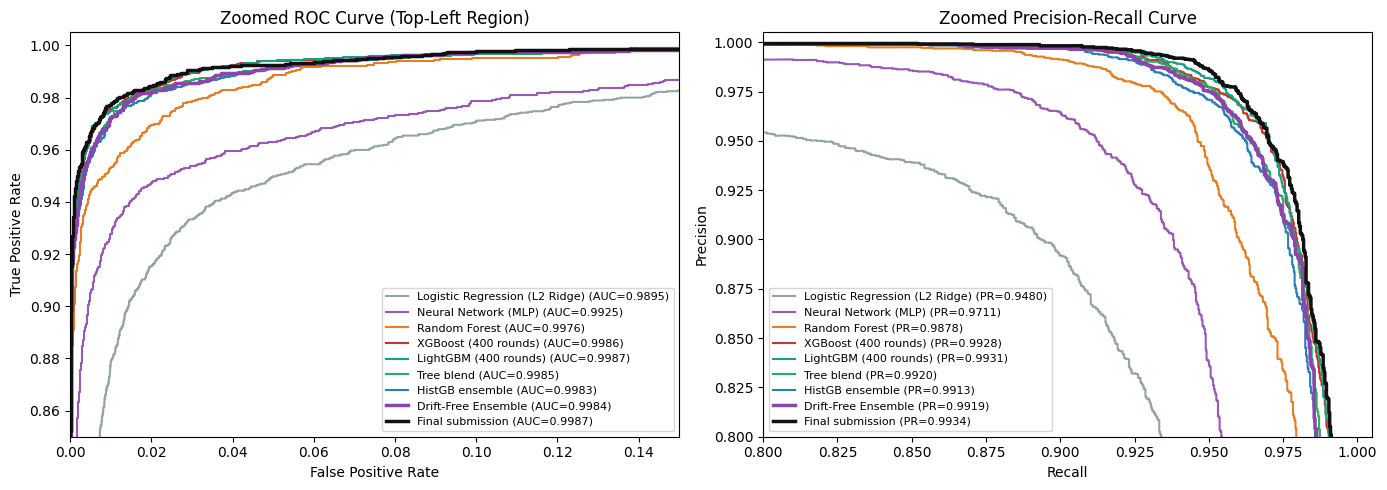

In [17]:
# Zoomed ROC and Precision-Recall curves (out-of-fold)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_models = [
    ('Logistic Regression (L2 Ridge)', '#95a5a6'), ('Neural Network (MLP)', '#9b59b6'),
    ('Random Forest', '#e67e22'), ('XGBoost (400 rounds)', '#c0392b'), ('LightGBM (400 rounds)', '#16a085'),
    ('Tree blend', '#27ae60'), ('HistGB ensemble', '#2980b9'),
    ('Drift-Free Ensemble', '#8e44ad'),
    ('Final submission', '#111111'),
]
for label, color in plot_models:
    model_p = oof[label]
    lw = 2.5 if label in ('Drift-Free Ensemble', 'Final submission') else 1.5
    fpr, tpr, _ = roc_curve(y_full, model_p)
    axes[0].plot(fpr, tpr, label=f"{label} (AUC={roc_auc_score(y_full, model_p):.4f})", color=color, lw=lw)
    prec, rec, _ = precision_recall_curve(y_full, model_p)
    axes[1].plot(rec, prec, label=f"{label} (PR={average_precision_score(y_full, model_p):.4f})", color=color, lw=lw)
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4)
axes[0].set_xlim([0.0, 0.15]); axes[0].set_ylim([0.85, 1.005])
axes[0].set_title('Zoomed ROC Curve (Top-Left Region)')
axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right', fontsize=8)
axes[1].set_xlim([0.80, 1.005]); axes[1].set_ylim([0.80, 1.005])
axes[1].set_title('Zoomed Precision-Recall Curve')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left', fontsize=8)
plt.tight_layout()
plt.show()

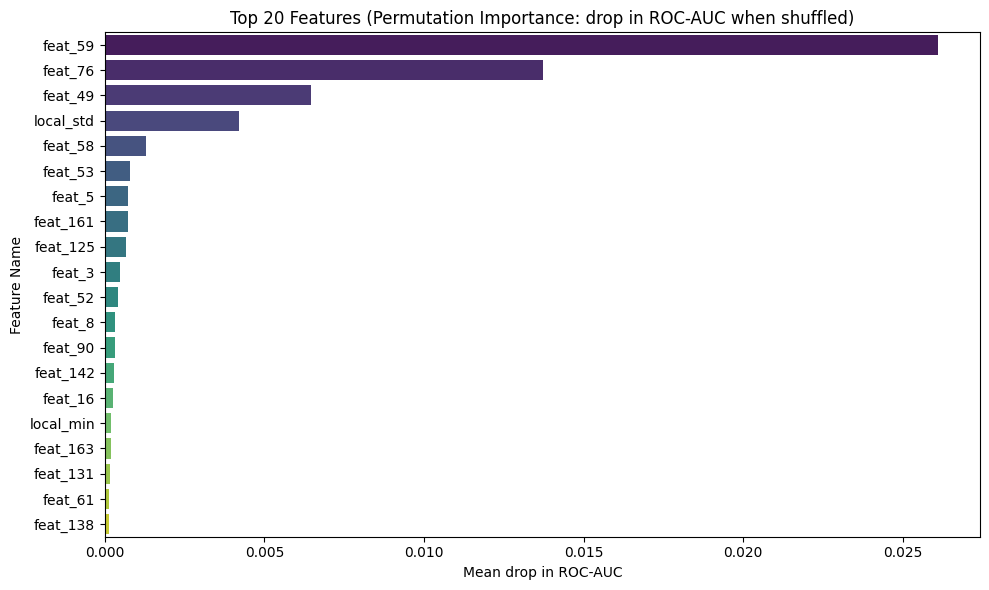

In [18]:
# Top 20 features by permutation importance (core HistGB model of the Drift-Free Ensemble, last fold, 179 features)
perm = permutation_importance(last_fold_core_model, X_final[last_fold_val_idx], y_full[last_fold_val_idx],
                              scoring='roc_auc', n_repeats=3, random_state=RANDOM_SEED, n_jobs=1)
imp_df = pd.DataFrame({'Feature': final_cols, 'Importance': perm.importances_mean}).sort_values('Importance', ascending=False).head(20)

plt.figure(figsize=(10, 6))
sns.barplot(data=imp_df, x='Importance', y='Feature', palette='viridis')
plt.title('Top 20 Features (Permutation Importance: drop in ROC-AUC when shuffled)')
plt.xlabel('Mean drop in ROC-AUC')
plt.ylabel('Feature Name')
plt.tight_layout()
plt.show()

In [19]:
# Best F1 cutoff and prediction entropy on the out-of-fold predictions of the final submission
ths_fine = np.linspace(0.05, 0.95, 91)
f1s_fine = [f1_score(y_full, (oof_final >= t).astype(int)) for t in ths_fine]
best_tau = ths_fine[np.argmax(f1s_fine)]
pred_labels = (oof_final >= best_tau).astype(int)
cm = confusion_matrix(y_full, pred_labels)

p_clip = np.clip(oof_final, 1e-7, 1 - 1e-7)
entropy = -p_clip * np.log2(p_clip) - (1 - p_clip) * np.log2(1 - p_clip)
high_conf_mask = entropy < 0.20

print(f"Optimal Decision Cutoff (τ*): {best_tau:.2f}")
print(f"OOF F1-Score at τ*:           {np.max(f1s_fine):.4f}")
print(f"OOF Precision at τ*:          {precision_score(y_full, pred_labels):.4f}")
print(f"OOF Recall at τ*:             {recall_score(y_full, pred_labels):.4f}")
print(f"Confusion Matrix at τ*={best_tau:.2f}:")
print(f"  True Licit (TN):   {cm[0,0]:,} | False Alarms (FP): {cm[0,1]:,}")
print(f"  Missed Fraud (FN): {cm[1,0]:,} | Caught Fraud (TP): {cm[1,1]:,}")
print(f"High-Confidence Decisions (Entropy < 0.20): {high_conf_mask.mean()*100:.1f}% of transactions (Accuracy: {(y_full[high_conf_mask] == pred_labels[high_conf_mask]).mean()*100:.2f}%)")

Optimal Decision Cutoff (τ*): 0.56
OOF F1-Score at τ*:           0.9680
OOF Precision at τ*:          0.9771
OOF Recall at τ*:             0.9591
Confusion Matrix at τ*=0.56:
  True Licit (TN):   27,509 | False Alarms (FP): 82
  Missed Fraud (FN): 149 | Caught Fraud (TP): 3,495
High-Confidence Decisions (Entropy < 0.20): 89.6% of transactions (Accuracy: 99.96%)


## 9. Final Test Predictions & File Generation
For the 15,329 test transactions, I average the Drift-Free Ensemble and the second blend 50/50 (each one averaged over its 5 fold models) and save the probabilities to `e1351028_v6.csv`.

In [ ]:
test_final_preds = 0.5 * test_second + 0.5 * test_drift_free

sub_df = pd.DataFrame({'index': test_df['index'].values, 'target': test_final_preds})
sub_df.to_csv('e1351028_v6.csv', index=False)
print("Saved predictions to e1351028_v6.csv.")

# Sanity checks on the submission file
assert len(sub_df) == 15329, "Incorrect row count!"
assert list(sub_df.columns) == ['index', 'target'], "Incorrect column names!"
assert (sub_df['target'] >= 0.0).all() and (sub_df['target'] <= 1.0).all(), "Predictions out of bounds!"
print("All sanity checks passed!")
print(f"Total rows: {len(sub_df):,} | Mean predicted illicit probability: {sub_df['target'].mean()*100:.2f}%")

# How many transactions get a high fraud score in each test time step
step_summary = pd.DataFrame({'time_step': test_df['time_step'].values, 'p': test_final_preds}).groupby('time_step')['p'].agg(
    transactions='size', score_ge_0_5=lambda s: int((s >= 0.5).sum()), score_ge_0_2=lambda s: int((s >= 0.2).sum()))
print("\nHigh-score transactions per test time step:")
print(step_summary.T.to_string())

print("\nFirst 10 rows:")
print(sub_df.head(10).to_string(index=False))

Saved predictions to e1351028_v6.csv.
All sanity checks passed!
Total rows: 15,329 | Mean predicted illicit probability: 7.09%

High-score transactions per test time step:
time_step       36   37   38    39    40    41    42    43    44    45   46   47   48   49
transactions  1708  498  756  1183  1211  1132  2154  1370  1591  1221  712  846  471  476
score_ge_0_5    43   29  106    79    83   114   212     2    22     9   11    2    2    5
score_ge_0_2   106   47  122   122   119   146   272    40   133    62   40   20    9   26

First 10 rows:
 index   target
     0 0.003137
     1 0.015610
     2 0.004205
     3 0.004096
     4 0.001604
     5 0.002607
     6 0.153145
     7 0.007820
     8 0.000605
     9 0.002779


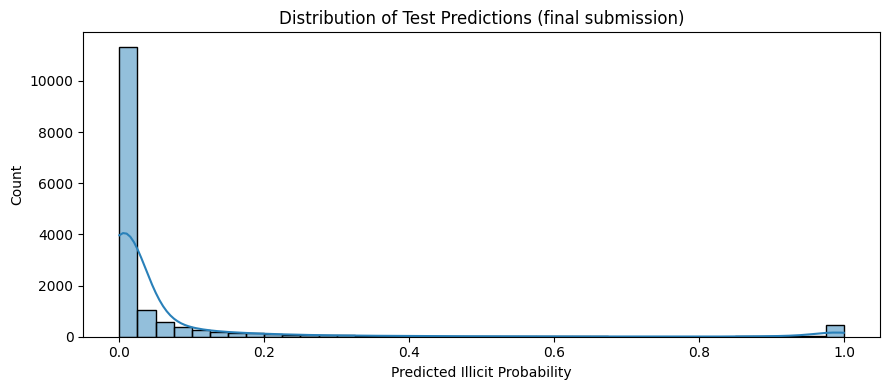

In [21]:
# Distribution of predicted test probabilities
plt.figure(figsize=(9, 4))
sns.histplot(sub_df['target'], bins=40, kde=True, color='#2980b9')
plt.title('Distribution of Test Predictions (final submission)')
plt.xlabel('Predicted Illicit Probability')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

## 10. References and Acknowledgements

### Academic References
* Weber, M., et al. (2019). *Anti-Money Laundering in Bitcoin: Experimenting with Graph Convolutional Networks for Financial Forensics*. KDD Workshop on Anomaly Detection in Finance ([arXiv:1908.02591](https://arxiv.org/abs/1908.02591)).
* Ashfaq, T., Khalid, R., et al. (2022). *A Machine Learning and Blockchain Based Efficient Fraud Detection Mechanism*. Sensors, 22(19), 7162 ([PMC9572131](https://pmc.ncbi.nlm.nih.gov/articles/PMC9572131/)).
* Jetty, N., et al. (2025). *Enhancing Bitcoin Fraud Detection with an Ensemble Model: A Deep Learning and Optimization-Based Approach*. ICoICC 2025 ([doi:10.1109/ICoICC64033.2025.11052038](https://doi.org/10.1109/ICoICC64033.2025.11052038)).
* Chawla, N. V., et al. (2002). *SMOTE: Synthetic Minority Over-sampling Technique*. Journal of Artificial Intelligence Research, 16, 321–357.
* Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2008). *Isolation Forest*. IEEE International Conference on Data Mining.
* Maganti, S. (2026). *When Graph Structure Becomes a Liability: A Critical Re-Evaluation of Graph Neural Networks for Bitcoin Fraud Detection under Temporal Distribution Shift* ([arXiv:2604.19514](https://arxiv.org/abs/2604.19514)).

### Online Code Examples and Implementation Sources
* **Scikit-learn User Guide & Examples**:
  - *Histogram-based Gradient Boosting*: [Scikit-learn HistGradientBoosting](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting) (number of rounds, leaf size, feature subsampling, and class weights).
  - *Permutation Importance*: [Scikit-learn Inspection](https://scikit-learn.org/stable/modules/permutation_importance.html) (feature importance measured by the drop in ROC-AUC).
  - *Robust Scaling*: [Scikit-learn Preprocessing](https://scikit-learn.org/stable/modules/preprocessing.html#scaling-data-with-outliers) (median and IQR scaling for skewed amounts).
  - *Stratified K-Fold*: [Scikit-learn Model Evaluation](https://scikit-learn.org/stable/modules/cross_validation.html#stratified-k-fold) (keeping the fraud rate equal across folds).
* **CatBoost, XGBoost & LightGBM Documentation**:
  - [CatBoost Documentation](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier), [XGBoost Documentation](https://xgboost.readthedocs.io/en/stable/python/python_api.html), [LightGBM Documentation](https://lightgbm.readthedocs.io/en/latest/pythonapi/lightgbm.LGBMClassifier.html).
* **NetworkX Graph Algorithms**:
  - *PageRank & Connected Components*: [NetworkX Documentation](https://networkx.org/documentation/stable/reference/algorithms/index.html) (PageRank inside each time step and connected groups of transactions).

### AI Usage
* Used Gemini and Antigravity to help debug the codes, implementation logic, unblock blockers in code errors.
* Used Gemini to help refine and improve the language, structure and clarity in the final report.